# A single-event Fisher forecast

The core of `gwforge_fisher` for one binary: a zero-noise network, a waveform generator, the Fisher matrix and what it says about the measurement. Settings, priors and the DALI extension are described in {doc}`../fisher`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import warnings
import numpy
import pylab
from GWForge.plotting import new_rcParams, palette, labels_for, corner_plot
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal  # noqa: E402, F401

pylab.rcParams.update(new_rcParams())
colours, colormap = palette()


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# A GW150914-like binary in a CE40 + CE20 network. IMRPhenomXHM at 1024 Hz
# over 8 s keeps every cell in this notebook at a few seconds.
# ══════════════════════════════════════════════════════════════════════════════
import bilby
from GWForge.ifo.detectors import Network
from GWForge.fisher import FisherMatrix, covariance
from GWForge.fisher.plot import samples_from_covariance

bilby.core.utils.setup_logger(log_level="error")

GPS_TIME, DURATION, FS, F_MIN = 1126259642.413, 8.0, 1024.0, 20.0

parameters = dict(
    chirp_mass=28.0, symmetric_mass_ratio=0.24, chi_1=0.3, chi_2=-0.2,
    luminosity_distance=1500.0, theta_jn=0.7, psi=0.9, phase=1.3,
    geocent_time=GPS_TIME, ra=1.375, dec=-1.2108,
)

def network(names):
    ifos = Network(ifos=names).initialise_ifos()
    ifos.set_strain_data_from_zero_noise(
        sampling_frequency=FS, duration=DURATION, start_time=GPS_TIME - DURATION + 2
    )
    return ifos

waveform_generator = bilby.gw.WaveformGenerator(
    duration=DURATION,
    sampling_frequency=FS,
    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
    parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
    waveform_arguments=dict(waveform_approximant="IMRPhenomXHM", reference_frequency=F_MIN, minimum_frequency=F_MIN),
)

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# The Fisher matrix. Five parameters (distance, time, psi, ra, dec) have exact
# derivatives; the other six are finite differences with calibrated steps.
# ══════════════════════════════════════════════════════════════════════════════
fisher = FisherMatrix(network(["CE40", "CE20"]), waveform_generator, parameters)

for name, snr in fisher.optimal_snrs.items():
    print(f"{name:8s} optimal SNR {snr:7.1f}")
print()
for name, sigma in fisher.sigmas.items():
    print(f"{name:22s} {parameters[name]:14.4f}  ±{sigma:10.3g}")

cov, info = covariance(fisher.matrix, names=fisher.names)
print(f"\ncondition number {info['condition_number']:.2e}")

CE40     optimal SNR   308.8
CE20     optimal SNR   168.5
network  optimal SNR   351.8

chirp_mass                    28.0000  ±    0.0224
symmetric_mass_ratio           0.2400  ±   0.00116
luminosity_distance         1500.0000  ±      38.8
ra                             1.3750  ±    0.0334
dec                           -1.2108  ±   0.00473
theta_jn                       0.7000  ±    0.0402
psi                            0.9000  ±     0.051
geocent_time           1126259642.4130  ±  0.000189
phase                          1.3000  ±     0.032
chi_1                          0.3000  ±      0.04
chi_2                         -0.2000  ±    0.0729

condition number 4.09e+05


network SNR 351.8 -> 399.7 with ET


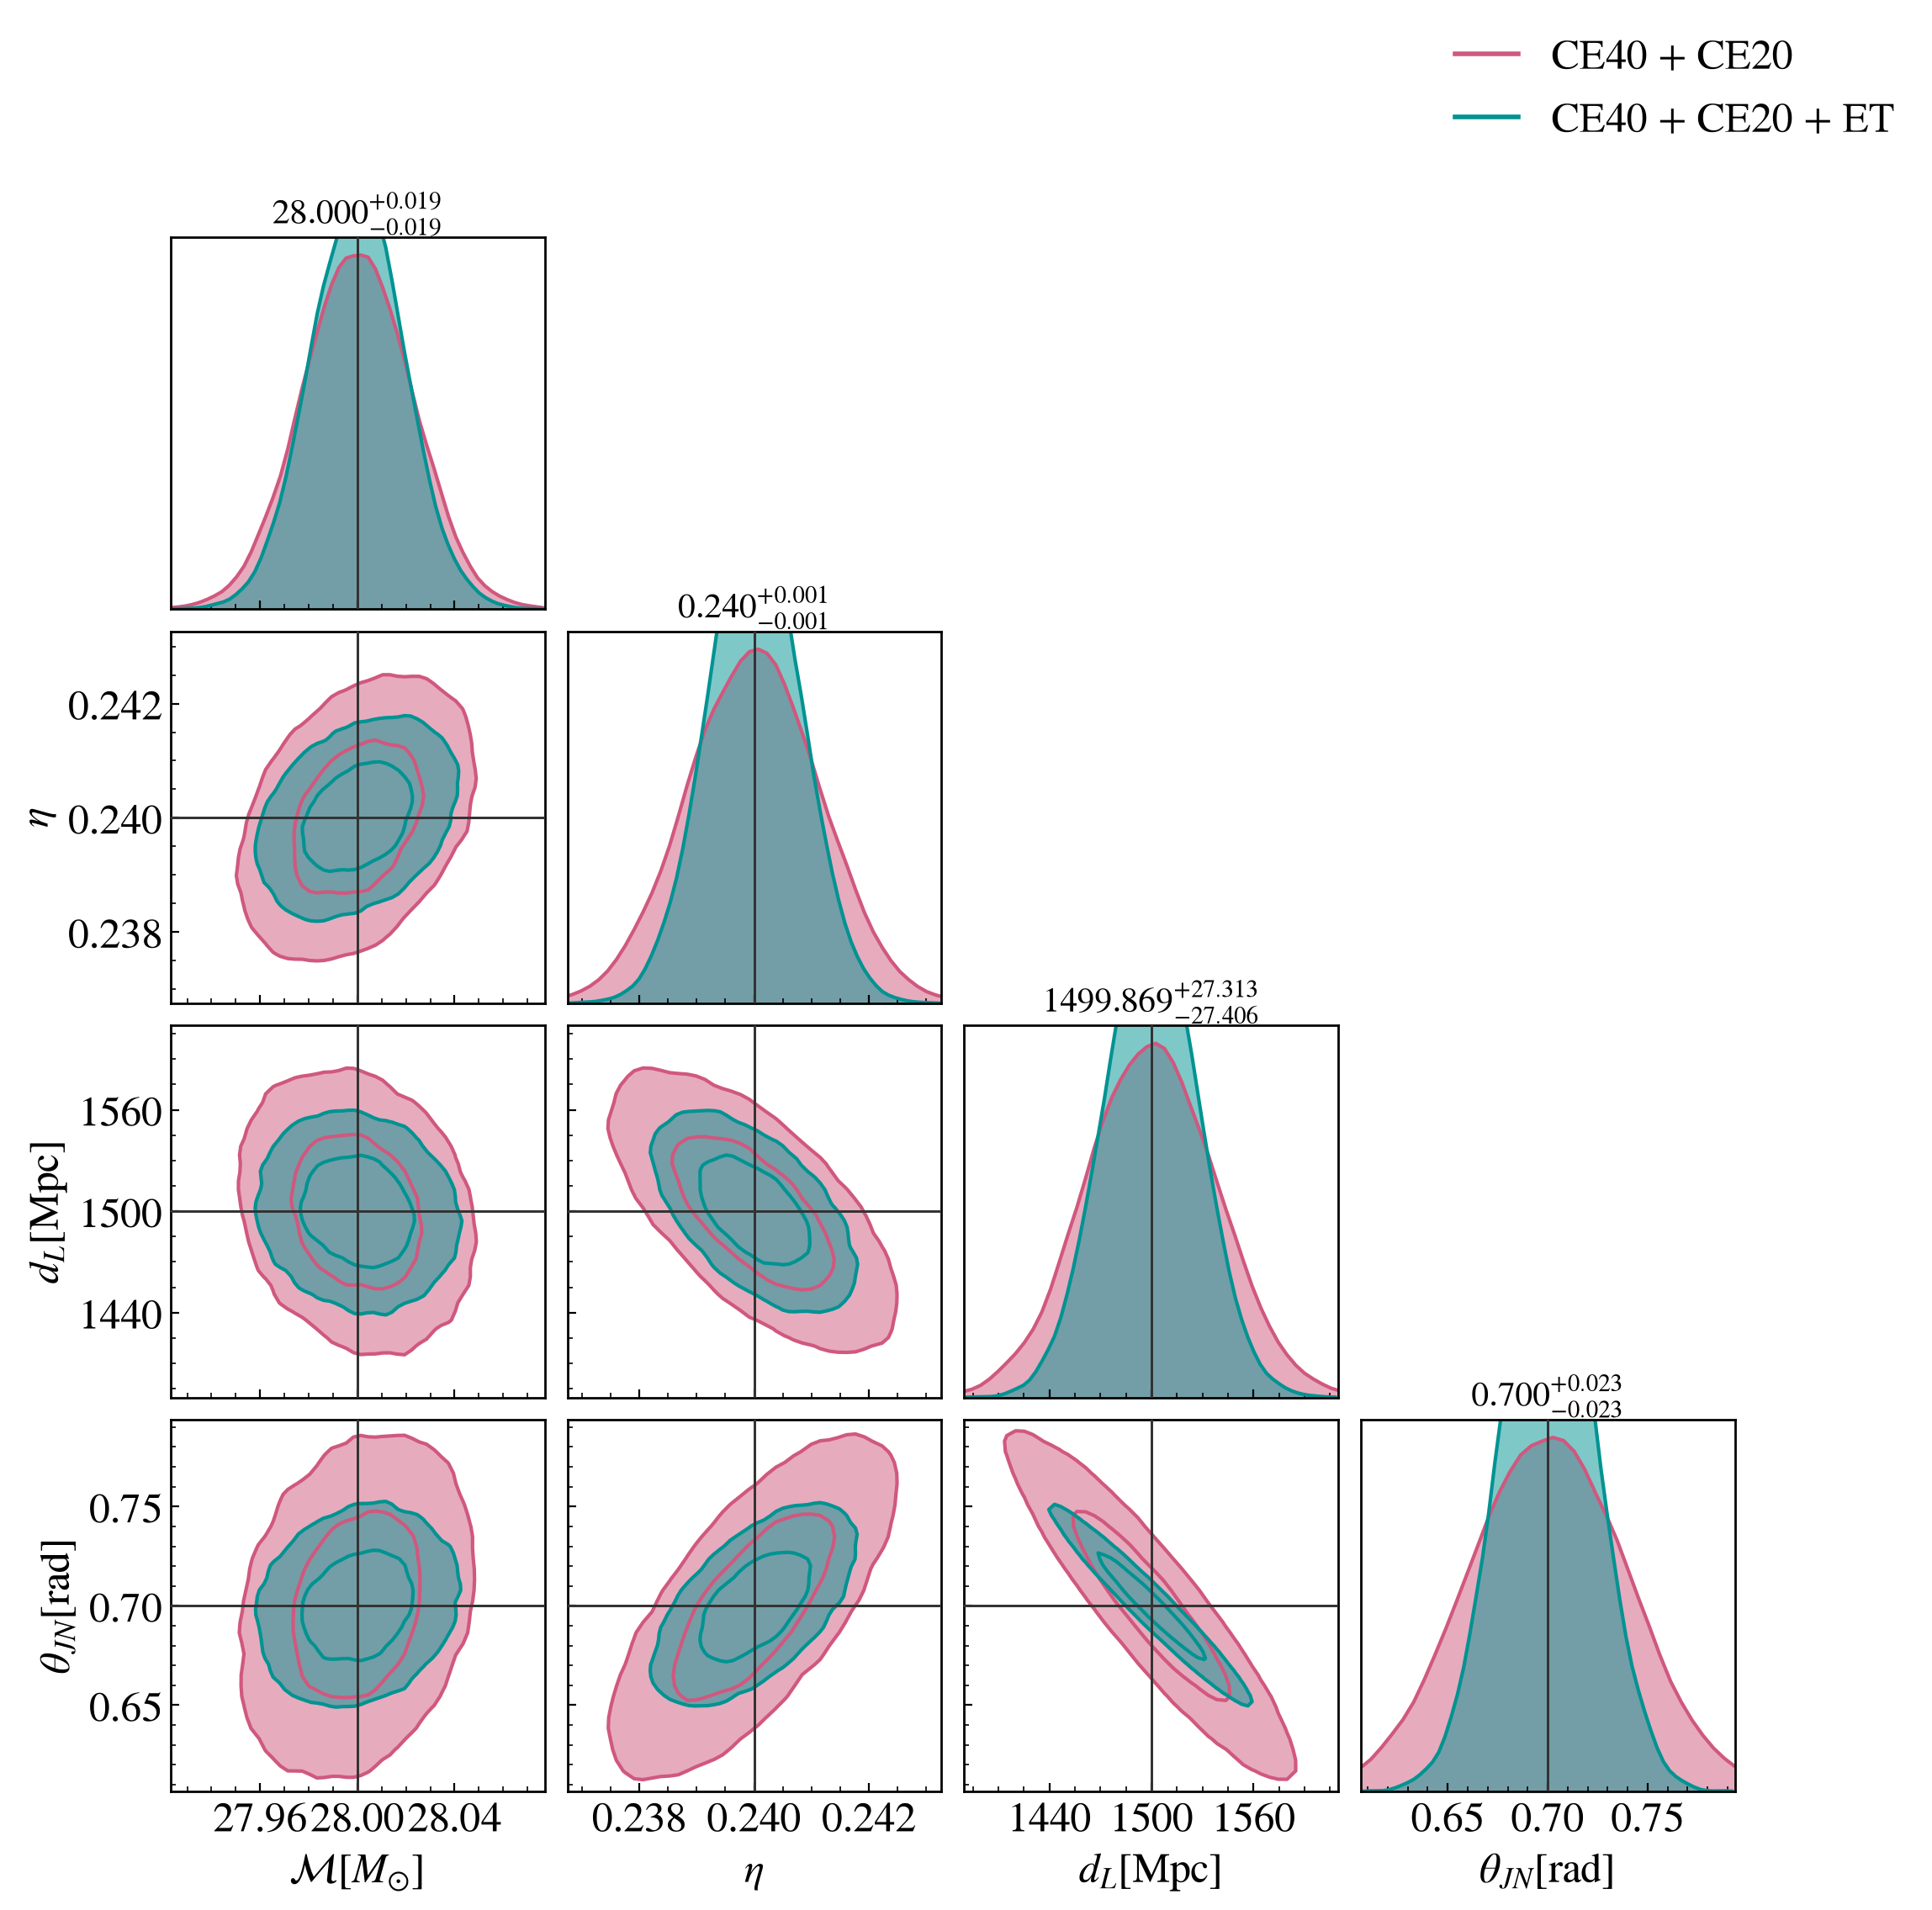

In [4]:
# ── What ET adds: the same event in CE40 + CE20 + ET ──────────────────────────
# ET enters as three interferometers; the Fisher matrix is a sum over all five.
fisher_et = FisherMatrix(network(["CE40", "CE20", "ET"]), waveform_generator, parameters)
print(f"network SNR {fisher.optimal_snrs['network']:.1f} -> {fisher_et.optimal_snrs['network']:.1f} with ET")

names = ["chirp_mass", "symmetric_mass_ratio", "luminosity_distance", "theta_jn"]
index = [fisher.names.index(n) for n in names]
mean = [parameters[n] for n in fisher.names]
truths = [parameters[n] for n in names]

samples_two = samples_from_covariance(mean, fisher.covariance, size=50000, seed=1)
samples_three = samples_from_covariance(mean, fisher_et.covariance, size=50000, seed=2)

# The broader posterior goes first so that it sets the panel ranges.
fig = corner_plot(samples_two[:, index], labels=labels_for(names), truths=truths, colour=colours[1], label="CE40 + CE20")
fig = corner_plot(samples_three[:, index], labels=labels_for(names), truths=truths, colour=colours[0], label="CE40 + CE20 + ET", fig=fig)

In [5]:
with_prior, _ = covariance(fisher.with_gaussian_prior({"theta_jn": 0.01}), names=fisher.names)
sigmas_with_prior = dict(zip(fisher.names, numpy.sqrt(numpy.diag(with_prior))))

for label, s in [("no prior", fisher.sigmas), ("sigma(theta_jn) = 0.01", sigmas_with_prior)]:
    print(f"{label:24s} sigma(d_L) = {s['luminosity_distance']:7.1f} Mpc   sigma(theta_jn) = {s['theta_jn']:.3f}")

no prior                 sigma(d_L) =    38.8 Mpc   sigma(theta_jn) = 0.040
sigma(theta_jn) = 0.01   sigma(d_L) =    16.8 Mpc   sigma(theta_jn) = 0.010


The CLI exposes the same knobs: `earth_rotation` and `finite_size` on the response, `order=2` for the DALI tensors and the posterior sampling that follows, and a prior file for the Gaussian constraints. Its corner plots come from `GWForge.fisher.plot.overlay_corner`, which does what the overlay above does with the `corner` package. See {doc}`../fisher` for the configuration.